<a href="https://colab.research.google.com/github/MD-Zahid-Hasan-Tushar/EXPLAINABLE_AI/blob/main/EXPLAINABLE_AI_FOR_ANOMALY_DETECTION_IN_HEALTHCARE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler

In [ ]:
def load_and_preprocess_data(file_path):
    """
    Load the dataset and preprocess it for modeling.

    Args:
        file_path (str): Path to the dataset file.

    Returns:
        pd.DataFrame: Preprocessed DataFrame.
    """
    try:
        # Load dataset
        df = pd.read_csv(file_path)

        # Drop unnecessary columns
        columns_to_drop = ['Name', 'Doctor', 'Hospital', 'Room Number']
        df = df.drop(columns=columns_to_drop, errors='ignore')

        # Convert date columns to datetime format
        df['Date of Admission'] = pd.to_datetime(df['Date of Admission'], errors='coerce')
        df['Discharge Date'] = pd.to_datetime(df['Discharge Date'], errors='coerce')

        # Create 'Length of Stay' feature
        df['Length of Stay'] = (df['Discharge Date'] - df['Date of Admission']).dt.days
        # Remove invalid 'Length of Stay'
        df = df[df['Length of Stay'] >= 0].dropna(subset=['Length of Stay'])

        # Encode categorical columns
        categorical_columns = [
            'Gender', 'Blood Type', 'Medical Condition', 'Insurance Provider',
            'Admission Type', 'Medication', 'Test Results'
        ]
        df = pd.get_dummies(df, columns=categorical_columns, drop_first=True)

        # Drop date columns
        df = df.drop(columns=['Date of Admission', 'Discharge Date'], errors='ignore')

        return df
    except Exception as e:
        print(f"Error during data loading and preprocessing: {e}")
        raise

In [ ]:
def split_and_scale_data(df, target_column, test_size=0.2, random_state=42):
    """
    Split the data into training and testing sets and scale features for SVM.

    Args:
        df (pd.DataFrame): Preprocessed DataFrame.
        target_column (str): Name of the target column.
        test_size (float): Proportion of test data.
        random_state (int): Random seed for reproducibility.

    Returns:
        tuple: X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled
    """

    try:
        # Define features and target
        X = df.drop(columns=[target_column])
        y = df[target_column]

        # Handle missing values in features
        X = X.fillna(X.mean())

        # Split data
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=random_state
        )

        # Scale features for SVM
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        return X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled
    except Exception as e:
        print(f"Error during data splitting and scaling: {e}")
        raise

In [ ]:
def train_models(X_train, X_test, y_train, X_train_scaled, X_test_scaled):
    """
    Train multiple regression models.

    Args:
        X_train, X_test: Training and testing feature sets.
        y_train: Training target set.
        X_train_scaled: Scaled training features for SVM.
        X_test_scaled: Scaled testing features for SVM.

    Returns:
        dict: Dictionary containing trained models and their predictions.
    """
    try:
        # Initialize models
        rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
        svm_model = SVR(kernel='rbf')
        gbr_model = GradientBoostingRegressor(random_state=42)
        xgb_model = XGBRegressor(random_state=42, n_jobs=-1)

        # Train models
        rf_model.fit(X_train, y_train)
        svm_model.fit(X_train_scaled, y_train)  # Use scaled data for SVM
        gbr_model.fit(X_train, y_train)
        xgb_model.fit(X_train, y_train)

        # Generate predictions
        rf_y_pred = rf_model.predict(X_test)
        svm_y_pred = svm_model.predict(X_test_scaled)  # Use scaled data for SVM
        gbr_y_pred = gbr_model.predict(X_test)
        xgb_y_pred = xgb_model.predict(X_test)

        # Example hybrid prediction (average of RF and GBR)
        hybrid_y_pred = (rf_y_pred + gbr_y_pred) / 2

        trained_models = {  # Corrected indentation
            'Random Forest': (rf_model, rf_y_pred),
            'SVM': (svm_model, svm_y_pred),
            'Gradient Boosting': (gbr_model, gbr_y_pred),
            'XGBoost': (xgb_model, xgb_y_pred),
            'Hybrid (RF + GBR)': (None, hybrid_y_pred)  # Hybrid has no model object
        }
        return trained_models
    except Exception as e:
        print(f"Error during model training: {e}")
        raise

In [ ]:
def evaluate_models(models, X_test, y_test):
    """
    Evaluate models using MSE, R2, and MAE metrics.

    Args:
        models (dict): Dictionary containing trained models and predictions.
        X_test: Testing feature set.
        y_test: Testing target set.

    Returns:
        dict: Dictionary containing evaluation metrics for each model.
    """
    try:
        results = {}
        for name, (_, y_pred) in models.items():  # Unpack consistently
            mse = mean_squared_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)
            mae = mean_absolute_error(y_test, y_pred)
            results[name] = {'MSE': mse, 'R2': r2, 'MAE': mae}
        return results
    except Exception as e:
        print(f"Error during model evaluation: {e}")
        raise


In [ ]:
def visualize_results(y_test, models, results):
    """
    Visualize predicted vs actual values and comparison of metrics.

    Args:
         y_test: Testing target set.
         models (dict): Dictionary containing trained models and predictions.
         results (dict): Dictionary containing evaluation metrics.
    """
    try:
        for name, (_, y_pred) in models.items():
            plt.figure(figsize=(10, 6))
            plt.scatter(y_test, y_pred, alpha=0.5)
            plt.title(f'{name} - Predicted vs Actual')
            plt.xlabel('Actual')
            plt.ylabel('Predicted')
            plt.show()

        for metric in ['MSE', 'R2', 'MAE']:
            scores = {name: result[metric] for name, result in results.items()}
            plt.figure(figsize=(10, 6))
            sns.barplot(x=list(scores.keys()), y=list(scores.values()), palette='viridis')
            plt.title(f'{metric} Comparison')
            plt.ylabel(metric)
            plt.xticks(rotation=45)
            plt.show()

    except Exception as e:
        print(f"Error during visualization: {e}")
        raise

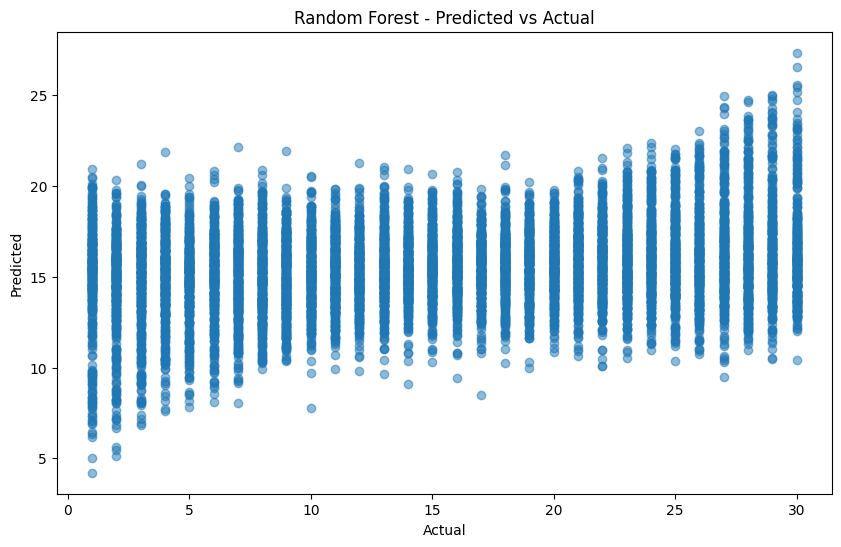

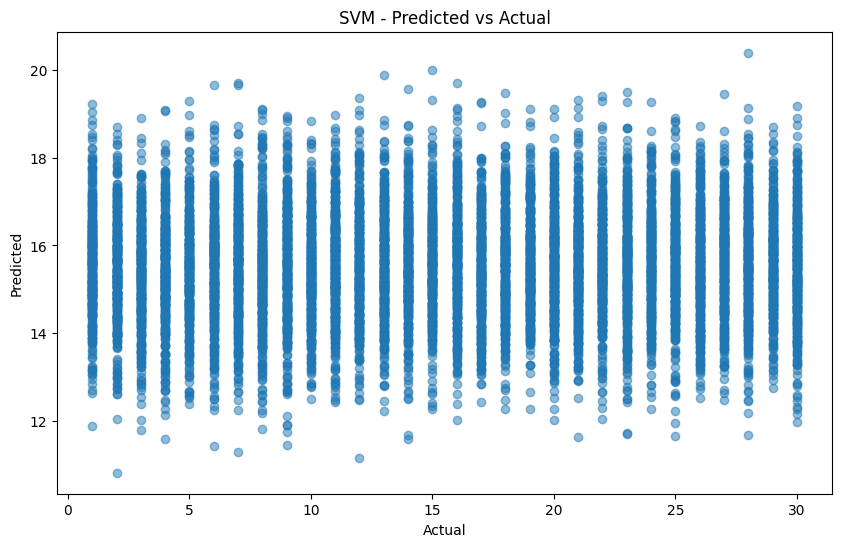

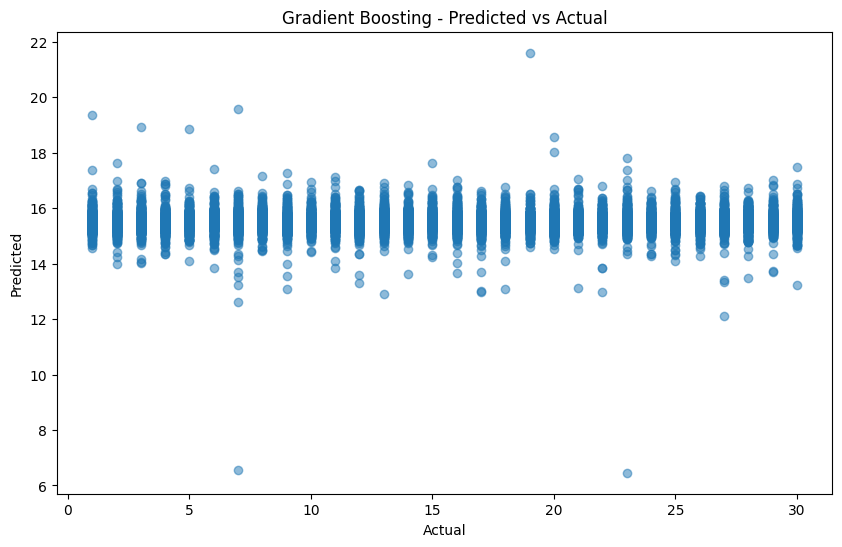

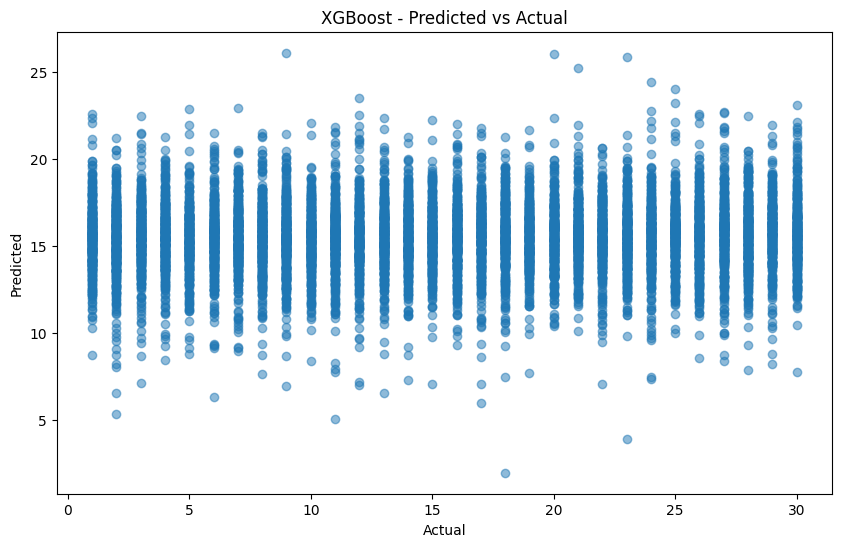

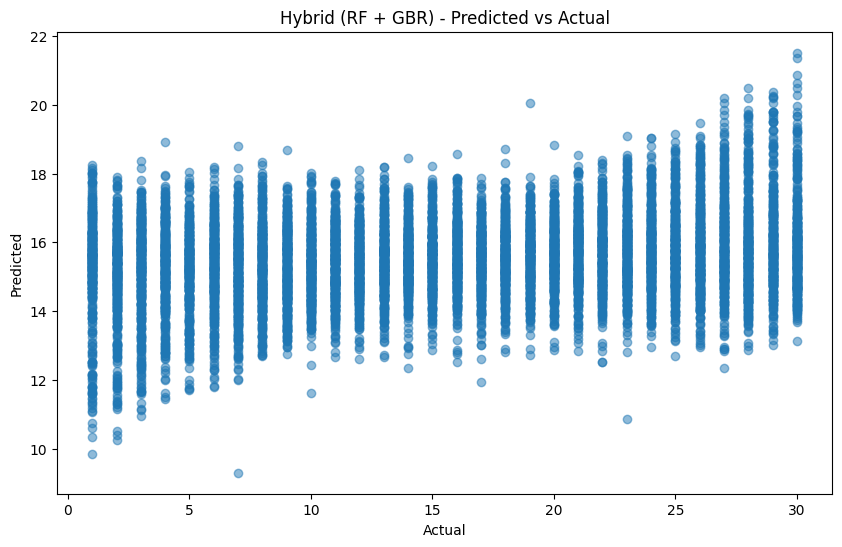

<ipython-input-6-d0ea90daa22c>:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(scores.keys()), y=list(scores.values()), palette='viridis')


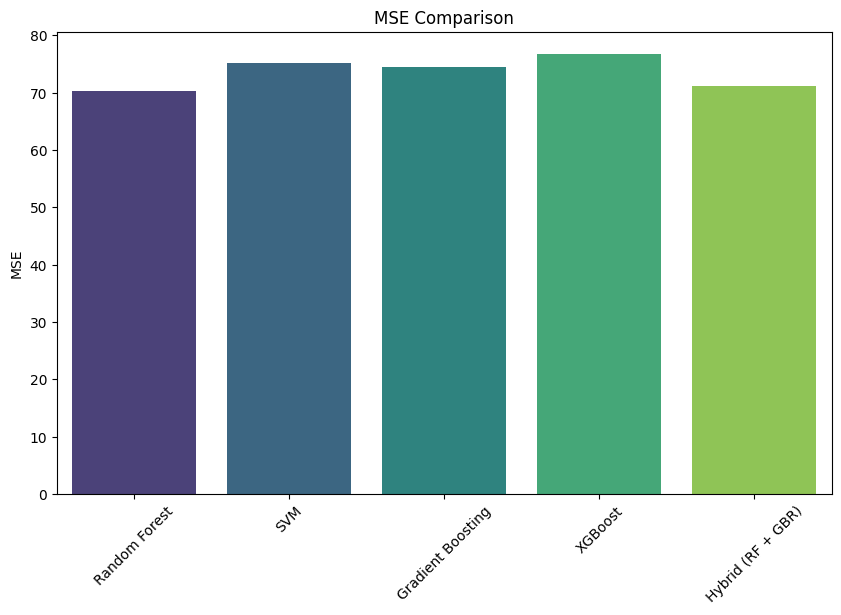

<ipython-input-6-d0ea90daa22c>:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(scores.keys()), y=list(scores.values()), palette='viridis')


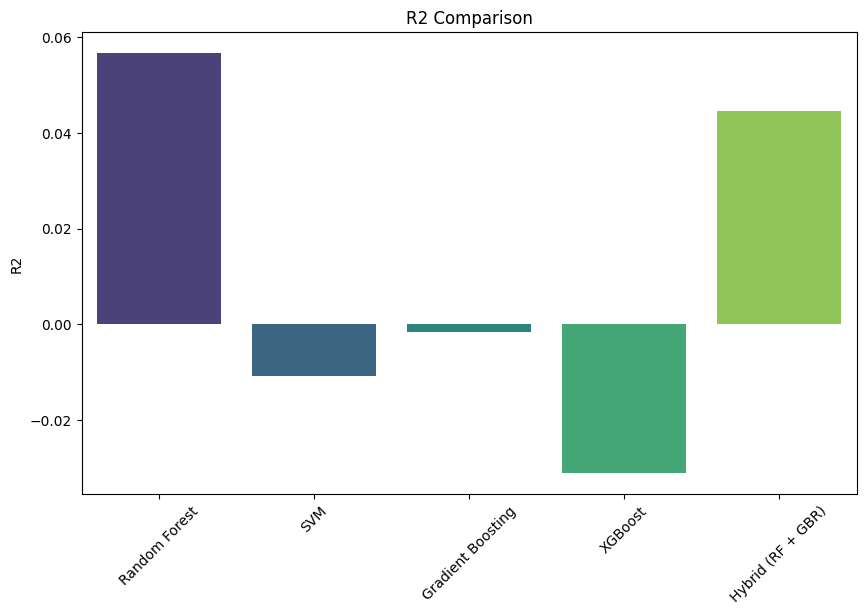

<ipython-input-6-d0ea90daa22c>:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(scores.keys()), y=list(scores.values()), palette='viridis')


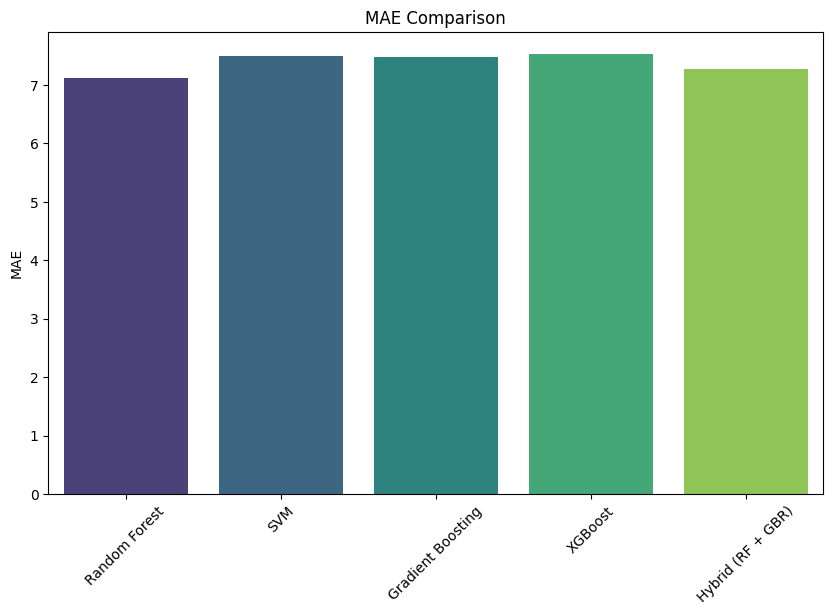


Random Forest Results:
MSE: 70.23691770270271, R2: 0.056621481982597754, MAE: 7.114136036036037

SVM Results:
MSE: 75.25581678915798, R2: -0.010789243560628714, MAE: 7.492516320541221

Gradient Boosting Results:
MSE: 74.57560313252019, R2: -0.0016530375264982577, MAE: 7.483638887497327

XGBoost Results:
MSE: 76.76103973388672, R2: -0.031006336212158203, MAE: 7.526737689971924

Hybrid (RF + GBR) Results:
MSE: 71.13174128278173, R2: 0.04460276916784822, MAE: 7.27485689199044

Best Models:
Best Model by MSE: Random Forest (MSE = 70.23691770270271)
Best Model by MAE: Random Forest (MAE = 7.114136036036037)
Best Model by R2: Random Forest (R2 = 0.056621481982597754)


In [ ]:
def main():
    """
    Main function to execute the entire pipeline.
    """
    try:
        # File path
        file_path = '/content/drive/MyDrive/CP/healthcare_dataset (2).csv'
        # Step 1: Load and preprocess data
        df = load_and_preprocess_data(file_path)

        # Step 2: Split and scale data
        X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled = split_and_scale_data(
            df, target_column='Length of Stay'
        )
        # Step 3: Train models
        models = train_models(X_train, X_test, y_train, X_train_scaled, X_test_scaled)

        # Step 4: Evaluate models
        results = evaluate_models(models, X_test, y_test)

        # Step 5: Visualize results
        visualize_results(y_test, models, results)

        # Print results
        for name, metrics in results.items():
            print(f"\n{name} Results:")
            print(f"MSE: {metrics['MSE']}, R2: {metrics['R2']}, MAE: {metrics['MAE']}")

        # Determine the best model for each metric
        best_mse_model = min(results, key=lambda x: results[x]['MSE'])
        best_mae_model = min(results, key=lambda x: results[x]['MAE'])
        best_r2_model = max(results, key=lambda x: results[x]['R2'])

        print("\nBest Models:")
        print(f"Best Model by MSE: {best_mse_model} (MSE = {results[best_mse_model]['MSE']})")
        print(f"Best Model by MAE: {best_mae_model} (MAE = {results[best_mae_model]['MAE']})")
        print(f"Best Model by R2: {best_r2_model} (R2 = {results[best_r2_model]['R2']})")


    except Exception as e:
        print(f"Pipeline failed with error: {e}")

if __name__ == "__main__":
    main()
